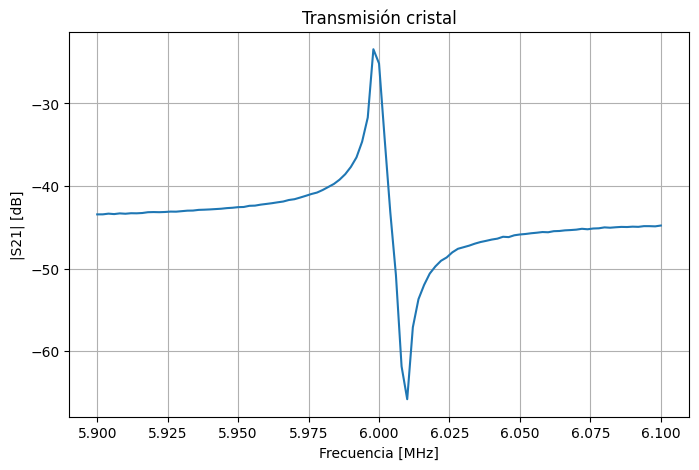

In [1]:
import numpy as np
import matplotlib.pyplot as plt

filename = "../../Mediciones/cristal_6Mhz.s2p"

freq = []

s21_re = []
s21_im = []

with open(filename, "r") as f:

    for line in f:

        line = line.strip()

        if not line or line.startswith("#") or line.startswith("!"):
            continue

        parts = line.split()

        freq.append(float(parts[0]))

        s21_re.append(float(parts[3]))
        s21_im.append(float(parts[4]))

freq = np.array(freq)

S21 = np.array(s21_re) + 1j*np.array(s21_im)

# Magnitud en dB
S21_db = 20 * np.log10(np.abs(S21))

plt.figure(figsize=(8,5))

plt.plot(freq/1e6, S21_db)

plt.xlabel("Frecuencia [MHz]")
plt.ylabel("|S21| [dB]")
plt.title("Transmisión cristal")
plt.grid(True)

plt.show()

## **Temperatura**

Se midió la variacion de 2 termistores barriendo la temperatura desde temperatura ambiente hasta 60 grados Celsius. 

Relación obtenida:
T1 = 1.029769 * T2 + -4.039333

Estadísticas de los residuos:
Media = 0.00000 °C
STD   = 1.38866 °C
RMS   = 1.38834 °C


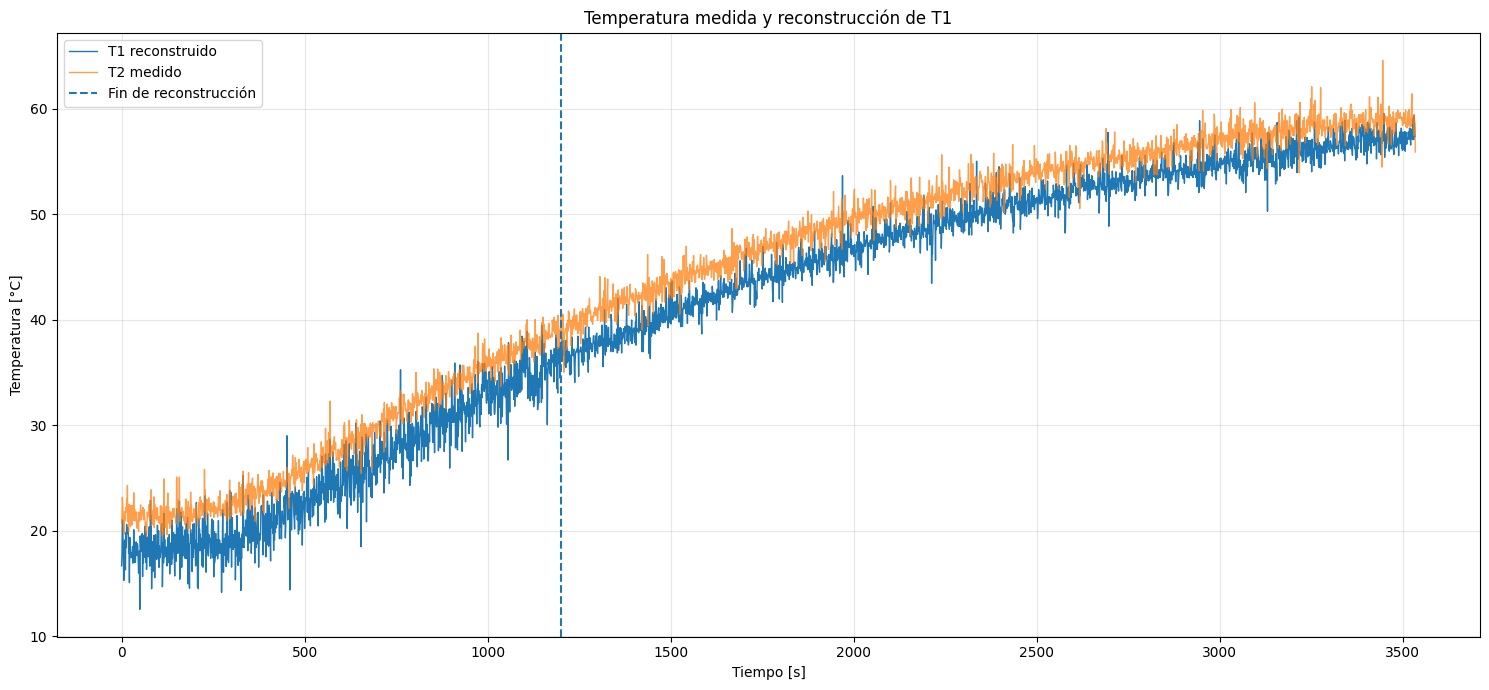


Archivo guardado como: temperaturas_reconstruidas.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# CONFIGURACIÓN
# ============================================================

archivo = "temperaturas.csv"

# A partir de este instante consideramos válida la medición de T1
t_inicio_valido = 1200

# Semilla para que la reconstrucción sea reproducible
SEMILLA = 42


# ============================================================
# CARGAR DATOS
# ============================================================

df = pd.read_csv(archivo)

# Región donde T1 se considera válido
validos = df["tiempo_s"] >= t_inicio_valido

T1 = df.loc[validos, "temp1_c"]
T2 = df.loc[validos, "temp2_c"]


# ============================================================
# AJUSTE LINEAL ENTRE T2 Y T1
#
#               T1 = a*T2 + b
# ============================================================

a, b = np.polyfit(T2, T1, 1)

print("Relación obtenida:")
print(f"T1 = {a:.6f} * T2 + {b:.6f}")


# ============================================================
# ESTIMACIÓN DE T1 A PARTIR DE T2
# ============================================================

df["temp1_estimado"] = (
    a * df["temp2_c"] + b
)


# ============================================================
# RESIDUOS EXPERIMENTALES
#
# e = T1_real - T1_estimado
# ============================================================

T1_pred_valido = a * T2 + b

residuos = (
    T1 - T1_pred_valido
).to_numpy()


# Estadísticas de los residuos

media_residuos = np.mean(residuos)

std_residuos = np.std(
    residuos,
    ddof=1
)

rms_residuos = np.sqrt(
    np.mean(residuos**2)
)


print("\nEstadísticas de los residuos:")
print(f"Media = {media_residuos:.5f} °C")
print(f"STD   = {std_residuos:.5f} °C")
print(f"RMS   = {rms_residuos:.5f} °C")


# ============================================================
# RECONSTRUCCIÓN DE LA REGIÓN INICIAL
# ============================================================

N_faltantes = (~validos).sum()

rng = np.random.default_rng(SEMILLA)


# Remuestreo aleatorio de los residuos experimentales
# con reemplazo

ruido_reconstruido = rng.choice(
    residuos,
    size=N_faltantes,
    replace=True
)


# Creamos la señal reconstruida partiendo de T1 real

df["temp1_reconstruido"] = df["temp1_c"].copy()


# Únicamente reemplazamos la región anterior a 1200 s

df.loc[~validos, "temp1_reconstruido"] = (
    df.loc[~validos, "temp1_estimado"].to_numpy()
    + ruido_reconstruido
)


# ============================================================
# GRÁFICO FINAL
# ============================================================

plt.figure(figsize=(15, 7))


# T1 reconstruido
plt.plot(
    df["tiempo_s"],
    df["temp1_reconstruido"],
    label="T1 reconstruido",
    linewidth=1.0
)


# T2 medido
plt.plot(
    df["tiempo_s"],
    df["temp2_c"],
    label="T2 medido",
    linewidth=1.0,
    alpha=0.75
)


# Marcamos el límite entre reconstrucción y medición real
plt.axvline(
    x=t_inicio_valido,
    linestyle="--",
    linewidth=1.5,
    label="Fin de reconstrucción"
)


plt.xlabel("Tiempo [s]")
plt.ylabel("Temperatura [°C]")

plt.title(
    "Temperatura medida y reconstrucción de T1"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# GUARDAR CSV CON LA RECONSTRUCCIÓN
# ============================================================

df.to_csv(
    "temperaturas_reconstruidas.csv",
    index=False
)

print(
    "\nArchivo guardado como: "
    "temperaturas_reconstruidas.csv"
)

In [3]:
# ============================================================
# ESTIMACIÓN DEL RUIDO / RESIDUO
# ============================================================

# Predicción de T1 en la zona donde ambos sensores funcionan
T1_pred_valido = a * T2 + b

# Diferencia entre T1 real y lo explicado por T2
residuos = T1 - T1_pred_valido

sigma_ruido = np.std(residuos, ddof=1)

print(f"Desvío estándar de los residuos: {sigma_ruido:.4f} °C")


# ============================================================
# RECONSTRUCCIÓN DE T1
# ============================================================

df["temp1_estimado"] = a * df["temp2_c"] + b

df["temp1_corregido"] = df["temp1_c"].copy()

# Ruido aleatorio con la misma desviación estándar observada
rng = np.random.default_rng(seed=42)

ruido = rng.normal(
    loc=0,
    scale=sigma_ruido,
    size=(~validos).sum()
)

df.loc[~validos, "temp1_corregido"] = (
    df.loc[~validos, "temp1_estimado"] + ruido
)

Desvío estándar de los residuos: 1.3887 °C


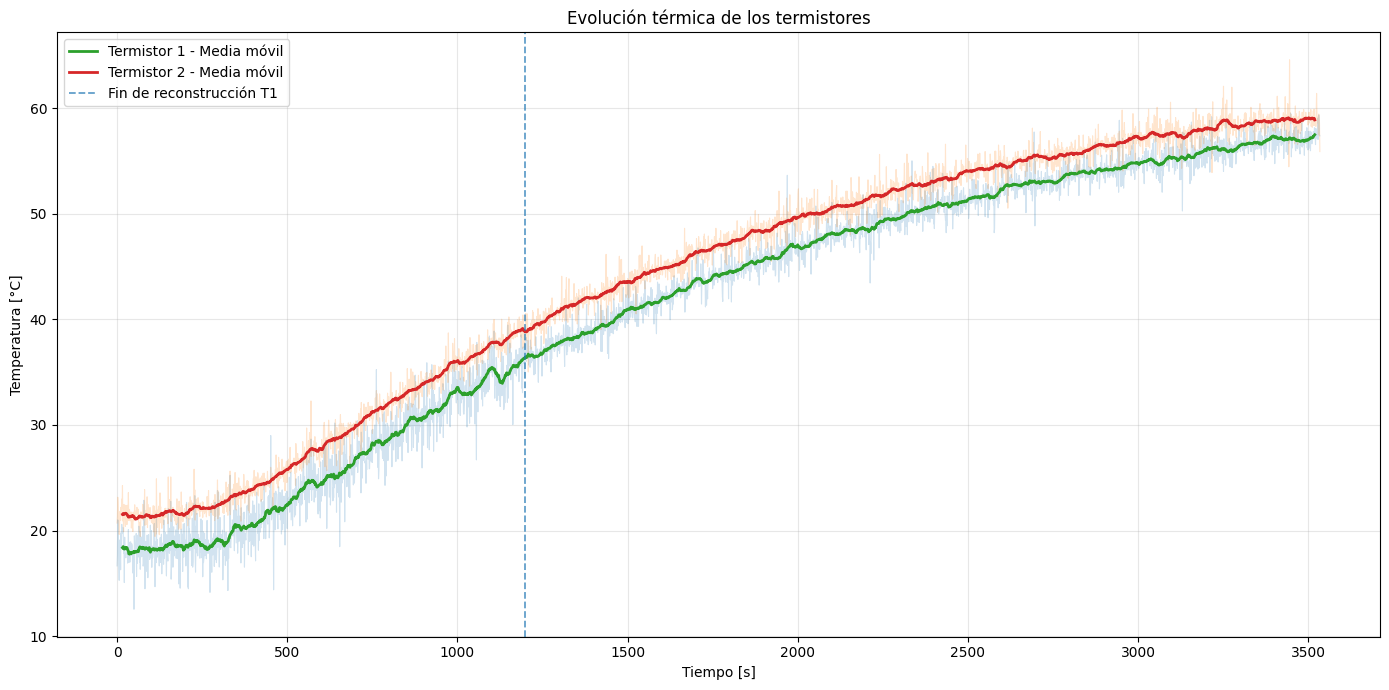

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CARGAR DATOS
# ============================================================

df = pd.read_csv("temperaturas_reconstruidas.csv")


# ============================================================
# MEDIA MÓVIL
# ============================================================

# 30 muestras ≈ 30 segundos
ventana = 30

# T1 reconstruido
df["temp1_ma"] = df["temp1_reconstruido"].rolling(
    window=ventana,
    center=True
).mean()

# T2 medido
df["temp2_ma"] = df["temp2_c"].rolling(
    window=ventana,
    center=True
).mean()


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(14, 7))

# ------------------------------------------------------------
# Datos crudos
# ------------------------------------------------------------

plt.plot(
    df["tiempo_s"],
    df["temp1_reconstruido"],
    alpha=0.20,
    linewidth=0.8
)

plt.plot(
    df["tiempo_s"],
    df["temp2_c"],
    alpha=0.20,
    linewidth=0.8
)


# ------------------------------------------------------------
# Medias móviles
# ------------------------------------------------------------

plt.plot(
    df["tiempo_s"],
    df["temp1_ma"],
    linewidth=2,
    label="Termistor 1 - Media móvil"
)

plt.plot(
    df["tiempo_s"],
    df["temp2_ma"],
    linewidth=2,
    label="Termistor 2 - Media móvil"
)


# ------------------------------------------------------------
# Marcamos dónde termina la reconstrucción
# ------------------------------------------------------------

plt.axvline(
    x=1200,
    linestyle="--",
    linewidth=1.3,
    alpha=0.7,
    label="Fin de reconstrucción T1"
)


# ============================================================
# FORMATO
# ============================================================

plt.xlabel("Tiempo [s]")
plt.ylabel("Temperatura [°C]")

plt.title(
    "Evolución térmica de los termistores"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [5]:
# ============================================================
# DIFERENCIA TÉRMICA ENTRE TERMISTORES
# ============================================================

# T1 reconstruido:
#   t < 1200 s  -> estimado a partir de T2 + residuos
#   t >= 1200 s -> medición real de T1

df["delta_T"] = (
    df["temp2_c"]
    - df["temp1_reconstruido"]
)


# ============================================================
# MÉTRICAS
# ============================================================

print("Diferencia térmica T2 - T1 reconstruido")
print("------------------------------------------")

print(
    f"Media:             "
    f"{df['delta_T'].mean():.3f} °C"
)

print(
    f"Desviación std.:   "
    f"{df['delta_T'].std():.3f} °C"
)

print(
    f"Mínimo:            "
    f"{df['delta_T'].min():.3f} °C"
)

print(
    f"Máximo:            "
    f"{df['delta_T'].max():.3f} °C"
)

Diferencia térmica T2 - T1 reconstruido
------------------------------------------
Media:             2.738 °C
Desviación std.:   1.451 °C
Mínimo:            -3.846 °C
Máximo:            9.162 °C


['tiempo_s', 'temp1_c', 'temp2_c', 'adc1', 'adc2', 'voltaje1_v', 'voltaje2_v', 'temp1_estimado', 'temp1_reconstruido']


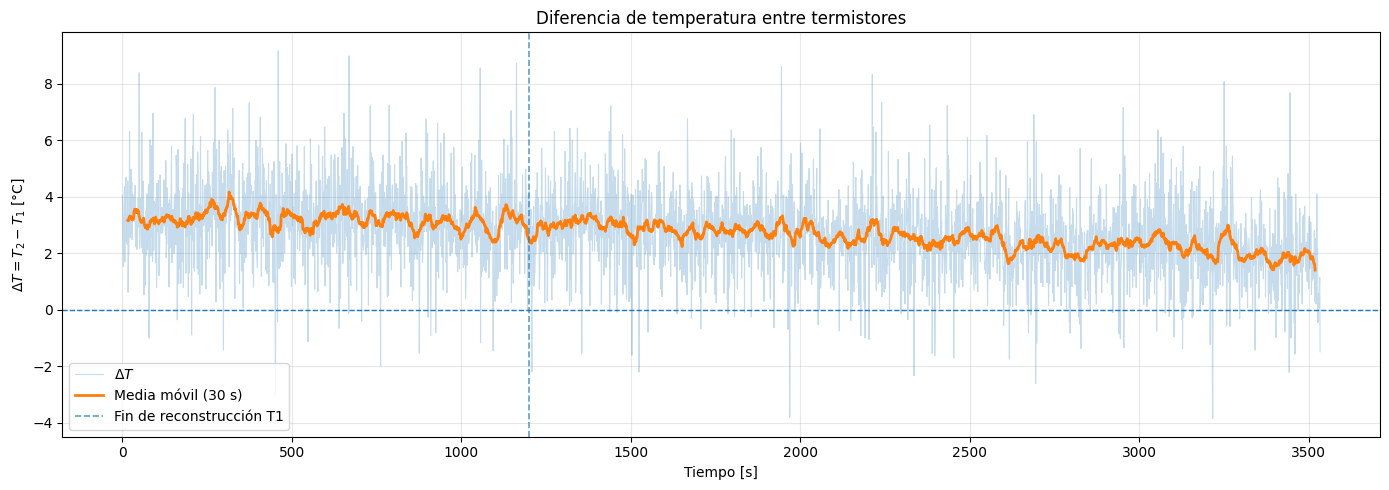

In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CARGAR DATOS
# ============================================================

df = pd.read_csv("temperaturas_reconstruidas.csv")

print(df.columns.tolist())


# ============================================================
# DIFERENCIA DE TEMPERATURA DURANTE TODO EL EXPERIMENTO
# ============================================================

# T1 reconstruido:
#   t < 1200 s  -> reconstrucción
#   t >= 1200 s -> medición real

df["delta_T"] = (
    df["temp2_c"]
    - df["temp1_reconstruido"]
)


# ============================================================
# MEDIA MÓVIL DE DELTA T
# ============================================================

ventana = 30

df["delta_T_ma"] = (
    df["delta_T"]
    .rolling(
        window=ventana,
        center=True
    )
    .mean()
)


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(14, 5))


# Datos crudos
plt.plot(
    df["tiempo_s"],
    df["delta_T"],
    alpha=0.25,
    linewidth=0.8,
    label=r"$\Delta T$"
)


# Media móvil
plt.plot(
    df["tiempo_s"],
    df["delta_T_ma"],
    linewidth=2,
    label="Media móvil (30 s)"
)


# Delta T = 0
plt.axhline(
    0,
    linestyle="--",
    linewidth=1
)


# Marcamos dónde termina la reconstrucción
plt.axvline(
    1200,
    linestyle="--",
    linewidth=1.2,
    alpha=0.7,
    label="Fin de reconstrucción T1"
)


# ============================================================
# FORMATO
# ============================================================

plt.xlabel("Tiempo [s]")
plt.ylabel(r"$\Delta T = T_2-T_1$ [°C]")

plt.title(
    "Diferencia de temperatura entre termistores"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

## **Resistencia**

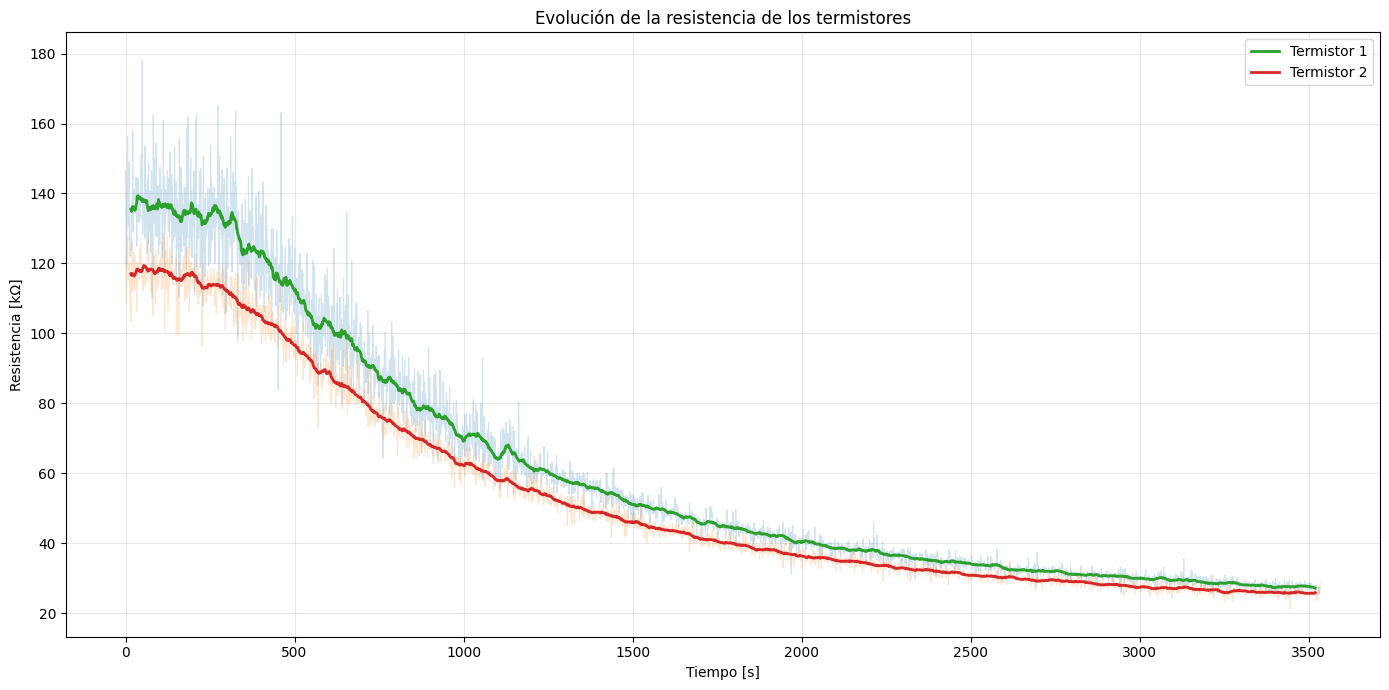

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# CARGAR DATOS
# ============================================================

df = pd.read_csv("temperaturas_reconstruidas.csv")


# ============================================================
# PARÁMETROS DEL NTC
# ============================================================

R0 = 100_000.0       # Resistencia nominal a 25 °C [ohm]
T0 = 25.0 + 273.15   # Temperatura nominal [K]
B  = 3950.0           # Constante Beta [K]

ventana = 30          # Media móvil ~30 s


# ============================================================
# TEMPERATURA -> RESISTENCIA
# ============================================================

def temperatura_a_resistencia(T_celsius):

    T_kelvin = T_celsius + 273.15

    return R0 * np.exp(
        B * (
            1.0 / T_kelvin
            - 1.0 / T0
        )
    )


# ============================================================
# CALCULAR RESISTENCIAS
# ============================================================

# Termistor 1:
# usamos la temperatura reconstruida para evitar
# las mediciones erróneas del tramo inicial
df["R1_kohm"] = (
    temperatura_a_resistencia(
        df["temp1_reconstruido"]
    ) / 1000
)


# Termistor 2:
# usamos la temperatura medida normalmente
df["R2_kohm"] = (
    temperatura_a_resistencia(
        df["temp2_c"]
    ) / 1000
)


# ============================================================
# MEDIA MÓVIL
# ============================================================

df["R1_ma"] = (
    df["R1_kohm"]
    .rolling(
        window=ventana,
        center=True
    )
    .mean()
)

df["R2_ma"] = (
    df["R2_kohm"]
    .rolling(
        window=ventana,
        center=True
    )
    .mean()
)


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(14, 7))


# Datos crudos
plt.plot(
    df["tiempo_s"],
    df["R1_kohm"],
    alpha=0.20,
    linewidth=0.8
)

plt.plot(
    df["tiempo_s"],
    df["R2_kohm"],
    alpha=0.20,
    linewidth=0.8
)


# Medias móviles
plt.plot(
    df["tiempo_s"],
    df["R1_ma"],
    linewidth=2,
    label="Termistor 1"
)

plt.plot(
    df["tiempo_s"],
    df["R2_ma"],
    linewidth=2,
    label="Termistor 2"
)


# ============================================================
# FORMATO
# ============================================================

plt.xlabel("Tiempo [s]")
plt.ylabel("Resistencia [kΩ]")

plt.title(
    "Evolución de la resistencia de los termistores"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

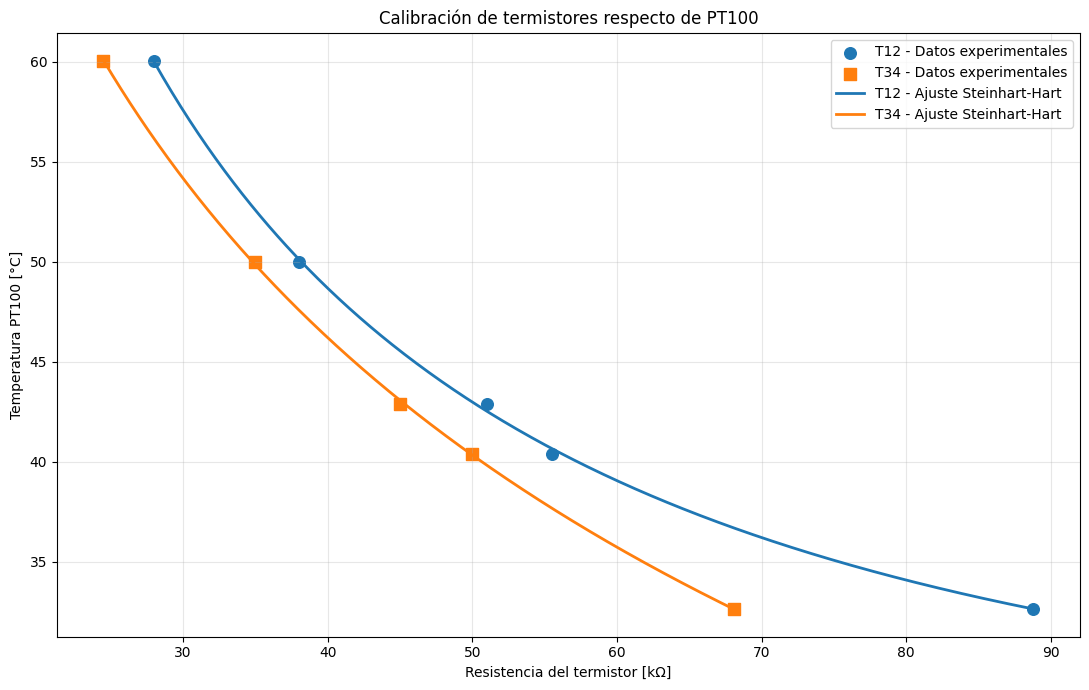

In [8]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DATOS EXPERIMENTALES DE CALIBRACIÓN
# ============================================================

# Temperatura obtenida a partir de la PT100 [°C]
T_pt100 = np.array([
    32.6525,
    40.4122,
    42.8732,
    50.0075,
    60.0211
])

# Resistencia termistor T12 [kΩ]
R_T12_kohm = np.array([
    88.8,
    55.5,
    51.0,
    38.0,
    28.0
])

# Resistencia termistor T34 [kΩ]
R_T34_kohm = np.array([
    68.1,
    50.0,
    45.0,
    35.0,
    24.5
])


# ============================================================
# COEFICIENTES STEINHART-HART
#
# 1/T = A + B ln(R) + C [ln(R)]³
#
# IMPORTANTE:
# R debe estar expresada en ohmios
# ============================================================

# Termistor T12
A_T12 = -5.58569877e-3
B_T12 =  1.09643128e-3
C_T12 = -2.45869025e-6

# Termistor T34
A_T34 =  1.97244127e-5
B_T34 =  3.08683338e-4
C_T34 = -1.34007171e-7


# ============================================================
# FUNCIÓN STEINHART-HART
# ============================================================

def steinhart_hart(R_ohm, A, B, C):

    lnR = np.log(R_ohm)

    T_kelvin = 1.0 / (
        A
        + B * lnR
        + C * lnR**3
    )

    return T_kelvin - 273.15


# ============================================================
# GENERAR CURVAS CONTINUAS
# ============================================================

# Rango de resistencia para cada termistor
R12_curva_kohm = np.linspace(
    R_T12_kohm.min(),
    R_T12_kohm.max(),
    500
)

R34_curva_kohm = np.linspace(
    R_T34_kohm.min(),
    R_T34_kohm.max(),
    500
)

# Convertimos kΩ -> Ω para Steinhart-Hart
T12_curva = steinhart_hart(
    R12_curva_kohm * 1000,
    A_T12,
    B_T12,
    C_T12
)

T34_curva = steinhart_hart(
    R34_curva_kohm * 1000,
    A_T34,
    B_T34,
    C_T34
)


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(11, 7))


# ------------------------------------------------------------
# Puntos experimentales
# ------------------------------------------------------------

plt.scatter(
    R_T12_kohm,
    T_pt100,
    s=70,
    label="T12 - Datos experimentales"
)

plt.scatter(
    R_T34_kohm,
    T_pt100,
    s=70,
    marker="s",
    label="T34 - Datos experimentales"
)


# ------------------------------------------------------------
# Curvas Steinhart-Hart
# ------------------------------------------------------------

plt.plot(
    R12_curva_kohm,
    T12_curva,
    linewidth=2,
    label="T12 - Ajuste Steinhart-Hart"
)

plt.plot(
    R34_curva_kohm,
    T34_curva,
    linewidth=2,
    label="T34 - Ajuste Steinhart-Hart"
)


# ============================================================
# FORMATO
# ============================================================

plt.xlabel("Resistencia del termistor [kΩ]")
plt.ylabel("Temperatura PT100 [°C]")

plt.title(
    "Calibración de termistores respecto de PT100"
)

plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [9]:
import pandas as pd
import numpy as np

# ============================================================
# CARGAR DATOS RECONSTRUIDOS
# ============================================================

df = pd.read_csv("temperaturas_reconstruidas.csv")


# ============================================================
# TEMPERATURA PT100 DEL PUNTO PROBLEMÁTICO
# ============================================================

T_objetivo = 32.6525


# ============================================================
# BUSCAR EL PUNTO MÁS CERCANO EN T1 RECONSTRUIDO
# ============================================================

idx = (
    df["temp1_reconstruido"] - T_objetivo
).abs().idxmin()

fila = df.loc[idx]

print("Punto reconstruido más cercano:")
print("--------------------------------")
print(f"Tiempo:           {fila['tiempo_s']:.2f} s")
print(f"T objetivo PT100: {T_objetivo:.4f} °C")
print(f"T1 reconstruido:  {fila['temp1_reconstruido']:.4f} °C")
print(f"T2 medida:        {fila['temp2_c']:.4f} °C")

Punto reconstruido más cercano:
--------------------------------
Tiempo:           1048.52 s
T objetivo PT100: 32.6525 °C
T1 reconstruido:  32.6473 °C
T2 medida:        36.5680 °C


In [10]:
# ============================================================
# TEMPERATURA -> RESISTENCIA NTC
# ============================================================

R0 = 100_000.0
T0 = 25.0 + 273.15
B = 3950.0

def temperatura_a_resistencia(T_celsius):

    T_kelvin = T_celsius + 273.15

    return R0 * np.exp(
        B * (
            1.0 / T_kelvin
            - 1.0 / T0
        )
    )


R_reconstruida = temperatura_a_resistencia(
    fila["temp1_reconstruido"]
)

print()
print("Resistencia reconstruida:")
print(f"R ≈ {R_reconstruida/1000:.3f} kΩ")


Resistencia reconstruida:
R ≈ 71.798 kΩ


STEINHART-HART T12
A = 1.2962790321e-03
B = 1.1750245787e-04
C = 4.7006761239e-07

STEINHART-HART T34
A = 1.9648148223e-05
B = 3.0869406086e-04
C = -1.3403841252e-07

CALIDAD DEL AJUSTE
RMSE T12 = 0.4778 °C
RMSE T34 = 0.1230 °C
Error máximo T12 = 0.8210 °C
Error máximo T34 = 0.2066 °C

RESIDUOS T12
T= 32.653 °C | R= 71.798 kΩ | residuo=-0.2597 °C
T= 40.412 °C | R= 55.500 kΩ | residuo=+0.3473 °C
T= 42.873 °C | R= 51.000 kΩ | residuo=+0.4305 °C
T= 50.008 °C | R= 38.000 kΩ | residuo=-0.8210 °C
T= 60.021 °C | R= 28.000 kΩ | residuo=+0.3065 °C


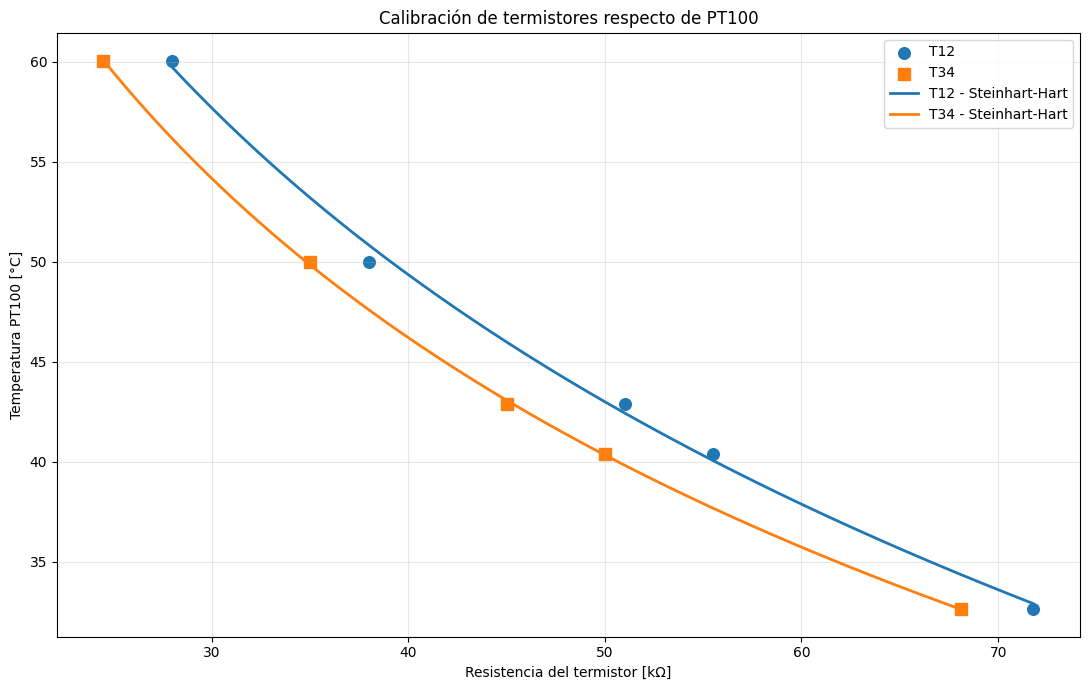

In [11]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# DATOS PT100
# ============================================================

T_pt100 = np.array([
    32.6525,
    40.4122,
    42.8732,
    50.0075,
    60.0211
])


# ============================================================
# TERMISTOR T12
#
# Primer punto reconstruido:
# 88.8 kΩ (inválido) -> 71.798 kΩ (estimado)
# ============================================================

R_T12_kohm = np.array([
    71.798,     # reconstruido
    55.5,
    51.0,
    38.0,
    28.0
])


# ============================================================
# TERMISTOR T34
#
# Se mantienen los datos experimentales originales
# ============================================================

R_T34_kohm = np.array([
    68.1,
    50.0,
    45.0,
    35.0,
    24.5
])


# ============================================================
# FUNCIÓN PARA AJUSTAR STEINHART-HART
#
# 1/T = A + B ln(R) + C ln(R)^3
# ============================================================

def ajustar_steinhart_hart(R_kohm, T_celsius):

    # kΩ -> Ω
    R = R_kohm * 1000.0

    # °C -> K
    T = T_celsius + 273.15

    lnR = np.log(R)

    # Matriz del modelo lineal
    X = np.column_stack([
        np.ones(len(R)),
        lnR,
        lnR**3
    ])

    y = 1.0 / T

    # Ajuste por mínimos cuadrados
    coef, _, _, _ = np.linalg.lstsq(
        X,
        y,
        rcond=None
    )

    A, B, C = coef

    return A, B, C


# ============================================================
# FUNCIÓN STEINHART-HART
# ============================================================

def steinhart_hart(R_kohm, A, B, C):

    R = np.asarray(R_kohm) * 1000.0

    lnR = np.log(R)

    T_kelvin = 1.0 / (
        A
        + B * lnR
        + C * lnR**3
    )

    return T_kelvin - 273.15


# ============================================================
# AJUSTES
# ============================================================

A12, B12, C12 = ajustar_steinhart_hart(
    R_T12_kohm,
    T_pt100
)

A34, B34, C34 = ajustar_steinhart_hart(
    R_T34_kohm,
    T_pt100
)


# ============================================================
# RESULTADOS DE LOS COEFICIENTES
# ============================================================

print("STEINHART-HART T12")
print("==============================")

print(f"A = {A12:.10e}")
print(f"B = {B12:.10e}")
print(f"C = {C12:.10e}")


print("\nSTEINHART-HART T34")
print("==============================")

print(f"A = {A34:.10e}")
print(f"B = {B34:.10e}")
print(f"C = {C34:.10e}")


# ============================================================
# TEMPERATURAS PREDICHAS
# ============================================================

T12_pred = steinhart_hart(
    R_T12_kohm,
    A12,
    B12,
    C12
)

T34_pred = steinhart_hart(
    R_T34_kohm,
    A34,
    B34,
    C34
)


# ============================================================
# RESIDUOS
# ============================================================

res12 = T_pt100 - T12_pred
res34 = T_pt100 - T34_pred


# ============================================================
# RMSE
# ============================================================

rmse12 = np.sqrt(
    np.mean(res12**2)
)

rmse34 = np.sqrt(
    np.mean(res34**2)
)


print("\nCALIDAD DEL AJUSTE")
print("==============================")

print(f"RMSE T12 = {rmse12:.4f} °C")
print(f"RMSE T34 = {rmse34:.4f} °C")

print(
    f"Error máximo T12 = "
    f"{np.max(np.abs(res12)):.4f} °C"
)

print(
    f"Error máximo T34 = "
    f"{np.max(np.abs(res34)):.4f} °C"
)


# ============================================================
# MOSTRAR RESIDUOS
# ============================================================

print("\nRESIDUOS T12")
print("==============================")

for T, R, res in zip(
    T_pt100,
    R_T12_kohm,
    res12
):

    print(
        f"T={T:7.3f} °C | "
        f"R={R:7.3f} kΩ | "
        f"residuo={res:+.4f} °C"
    )


# ============================================================
# GENERAR CURVAS CONTINUAS
# ============================================================

R12_curva = np.linspace(
    R_T12_kohm.min(),
    R_T12_kohm.max(),
    500
)

R34_curva = np.linspace(
    R_T34_kohm.min(),
    R_T34_kohm.max(),
    500
)


T12_curva = steinhart_hart(
    R12_curva,
    A12,
    B12,
    C12
)

T34_curva = steinhart_hart(
    R34_curva,
    A34,
    B34,
    C34
)


# ============================================================
# GRÁFICO
# ============================================================

plt.figure(figsize=(11, 7))


# ------------------------------------------------------------
# Puntos
# ------------------------------------------------------------

plt.scatter(
    R_T12_kohm,
    T_pt100,
    s=70,
    label="T12"
)

plt.scatter(
    R_T34_kohm,
    T_pt100,
    s=70,
    marker="s",
    label="T34"
)


# ------------------------------------------------------------
# Curvas Steinhart-Hart
# ------------------------------------------------------------

plt.plot(
    R12_curva,
    T12_curva,
    linewidth=2,
    label="T12 - Steinhart-Hart"
)

plt.plot(
    R34_curva,
    T34_curva,
    linewidth=2,
    label="T34 - Steinhart-Hart"
)


# ============================================================
# FORMATO
# ============================================================

plt.xlabel(
    "Resistencia del termistor [kΩ]"
)

plt.ylabel(
    "Temperatura PT100 [°C]"
)

plt.title(
    "Calibración de termistores respecto de PT100"
)

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.show()

## **Análisis de temperatura en vacío**

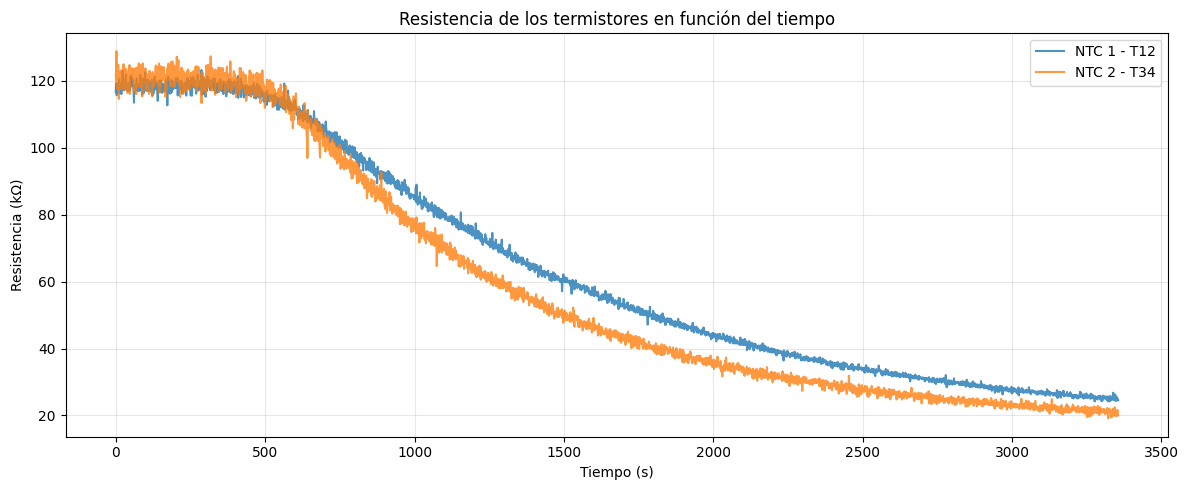

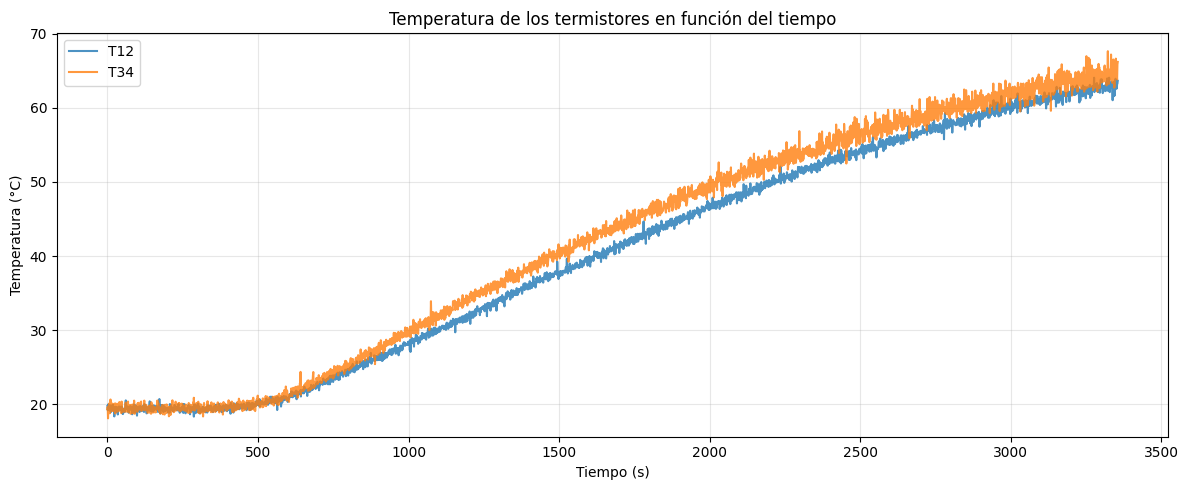

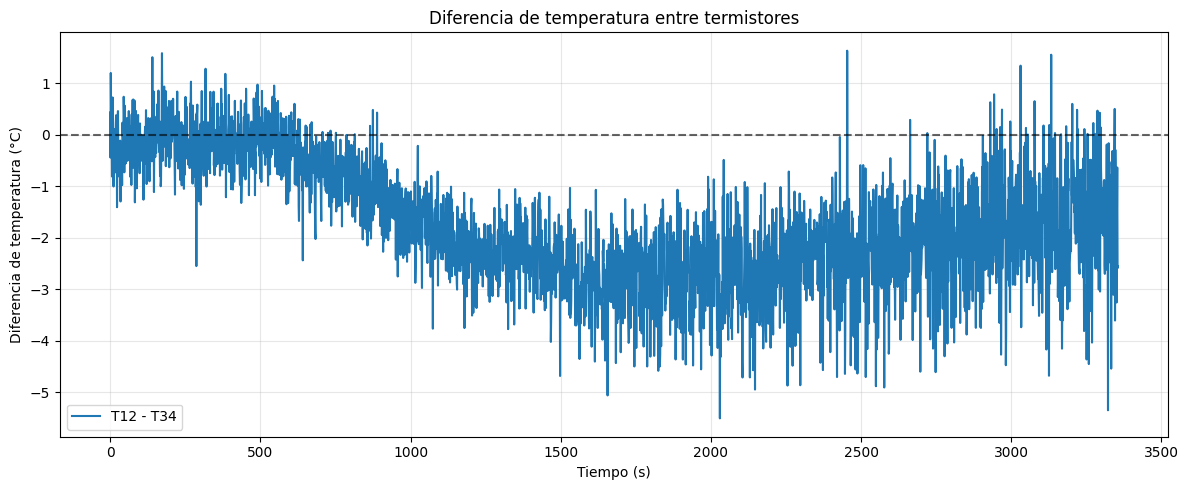

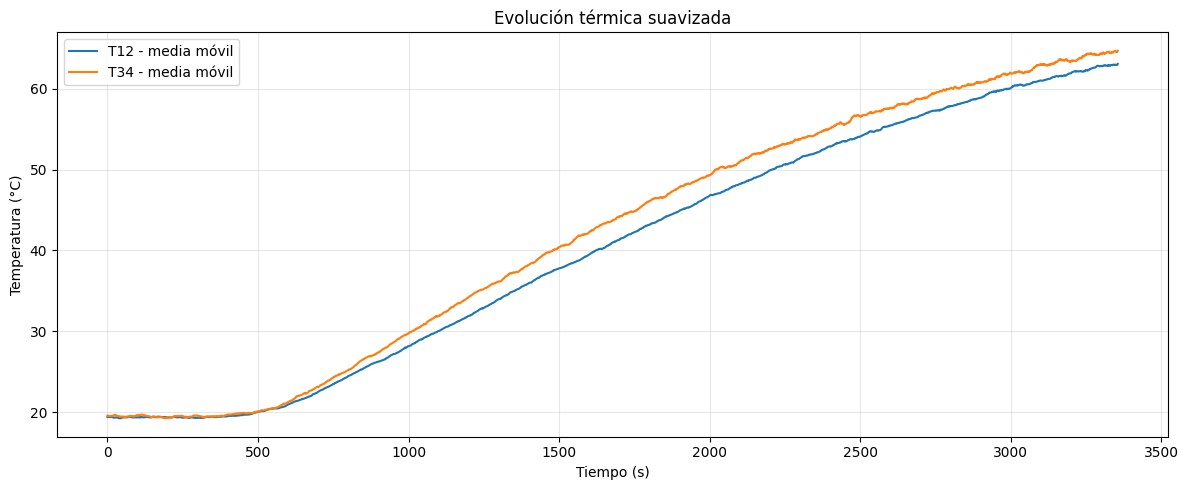


ESTADÍSTICAS DE LAS MEDICIONES
       r1_kohm   r2_kohm  temp1_c  temp2_c  delta_T
mean   64.2440   58.7755  40.2112  41.9555  -1.7444
std    33.4985   36.0379  15.0388  15.6899   1.2054
min    24.1664   19.1091  18.3250  18.0880  -5.5030
max   123.2803  128.9032  64.0660  67.6440   1.6340

ERROR MÁXIMO DE RECONSTRUCCIÓN
NTC 1: 0.000535 °C
NTC 2: 0.000537 °C

Archivo generado: temperaturas_vacio_analizadas.csv


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ============================================================
# CONFIGURACIÓN
# ============================================================

ARCHIVO = "temperaturas_vacio.csv"

R_FIJA = 100_000.0
VCC = 3.3
ADC_MAX = 65535.0

# Coeficientes Steinhart-Hart del firmware original

SH_A_1 = 1.2962790321e-03
SH_B_1 = 1.1750245787e-04
SH_C_1 = 4.7006761239e-07

SH_A_2 = 1.9648148223e-05
SH_B_2 = 3.0869406086e-04
SH_C_2 = -1.3403841252e-07

VENTANA_MEDIA = 30  # cantidad de muestras

# ============================================================
# CARGAR DATOS
# ============================================================

df = pd.read_csv(ARCHIVO)

df = df.sort_values("tiempo_s").reset_index(drop=True)

t = df["tiempo_s"].to_numpy()

# ============================================================
# RECONSTRUIR RESISTENCIAS
# ============================================================

# Usamos el ADC original para evitar errores de redondeo
# en los voltajes almacenados.

df["v1_reconstruido"] = df["adc1"] / ADC_MAX * VCC
df["v2_reconstruido"] = df["adc2"] / ADC_MAX * VCC

def calcular_resistencia(v):
    return R_FIJA * v / (VCC - v)

df["r1_ohm"] = calcular_resistencia(df["v1_reconstruido"])
df["r2_ohm"] = calcular_resistencia(df["v2_reconstruido"])

df["r1_kohm"] = df["r1_ohm"] / 1000
df["r2_kohm"] = df["r2_ohm"] / 1000

# ============================================================
# RECONSTRUIR TEMPERATURAS
# ============================================================

def steinhart_hart(R, A, B, C):
    ln_R = np.log(R)
    inv_T = A + B * ln_R + C * ln_R**3
    return 1 / inv_T - 273.15

df["T1_recalculada"] = steinhart_hart(
    df["r1_ohm"], SH_A_1, SH_B_1, SH_C_1
)

df["T2_recalculada"] = steinhart_hart(
    df["r2_ohm"], SH_A_2, SH_B_2, SH_C_2
)

df["delta_T"] = df["temp1_c"] - df["temp2_c"]

# ============================================================
# GRÁFICO 1: RESISTENCIA VS TIEMPO
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(t, df["r1_kohm"], label="NTC 1 - T12", alpha=0.8)
plt.plot(t, df["r2_kohm"], label="NTC 2 - T34", alpha=0.8)

plt.xlabel("Tiempo (s)")
plt.ylabel("Resistencia (kΩ)")
plt.title("Resistencia de los termistores en función del tiempo")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 2: TEMPERATURA VS TIEMPO
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(t, df["temp1_c"], label="T12", alpha=0.8)
plt.plot(t, df["temp2_c"], label="T34", alpha=0.8)

plt.xlabel("Tiempo (s)")
plt.ylabel("Temperatura (°C)")
plt.title("Temperatura de los termistores en función del tiempo")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 3: DIFERENCIA DE TEMPERATURA
# ============================================================

plt.figure(figsize=(12, 5))

plt.plot(t, df["delta_T"], label="T12 - T34")

plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.xlabel("Tiempo (s)")
plt.ylabel("Diferencia de temperatura (°C)")
plt.title("Diferencia de temperatura entre termistores")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# GRÁFICO 4: TEMPERATURAS SUAVIZADAS
# ============================================================

df["T1_media"] = df["temp1_c"].rolling(
    VENTANA_MEDIA, center=True, min_periods=1
).mean()

df["T2_media"] = df["temp2_c"].rolling(
    VENTANA_MEDIA, center=True, min_periods=1
).mean()

plt.figure(figsize=(12, 5))

plt.plot(t, df["T1_media"], label="T12 - media móvil")
plt.plot(t, df["T2_media"], label="T34 - media móvil")

plt.xlabel("Tiempo (s)")
plt.ylabel("Temperatura (°C)")
plt.title("Evolución térmica suavizada")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# ============================================================
# ESTADÍSTICAS
# ============================================================

columnas = [
    "r1_kohm", "r2_kohm",
    "temp1_c", "temp2_c", "delta_T"
]

print("\nESTADÍSTICAS DE LAS MEDICIONES")
print(df[columnas].agg(["mean", "std", "min", "max"]).round(4))

# ============================================================
# VERIFICAR RECONSTRUCCIÓN STEINHART-HART
# ============================================================

error1 = df["T1_recalculada"] - df["temp1_c"]
error2 = df["T2_recalculada"] - df["temp2_c"]

print("\nERROR MÁXIMO DE RECONSTRUCCIÓN")
print(f"NTC 1: {error1.abs().max():.6f} °C")
print(f"NTC 2: {error2.abs().max():.6f} °C")

# ============================================================
# EXPORTAR RESULTADOS
# ============================================================

df.to_csv("temperaturas_vacio_analizadas.csv", index=False)

print("\nArchivo generado: temperaturas_vacio_analizadas.csv")


## **Frecuencia del cristal vs temperatura**

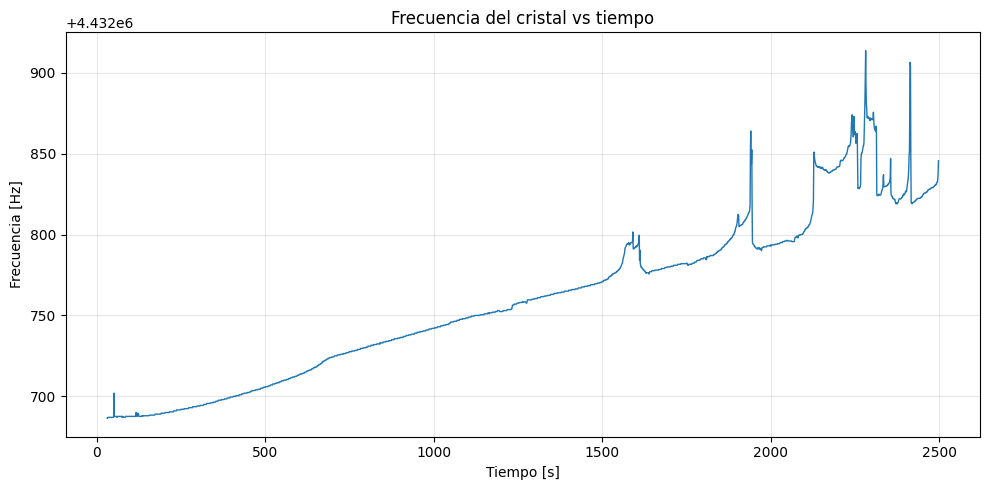

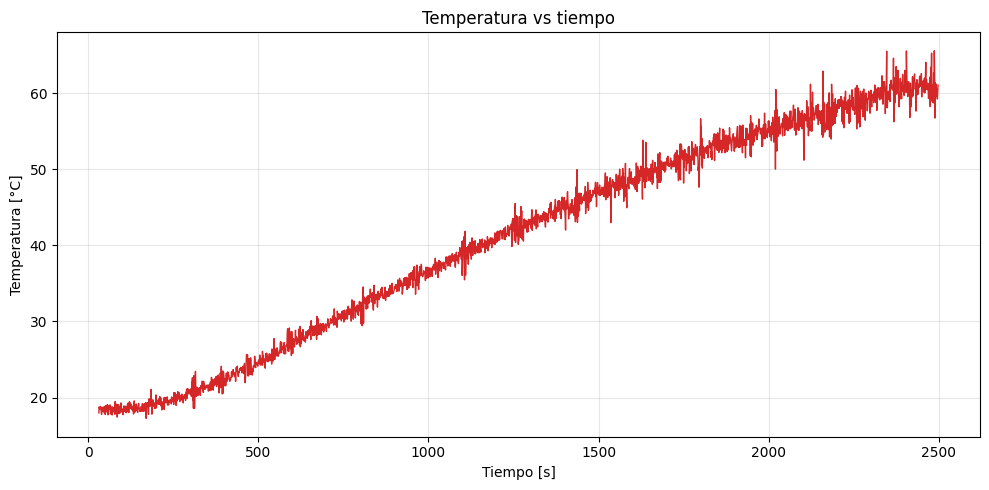

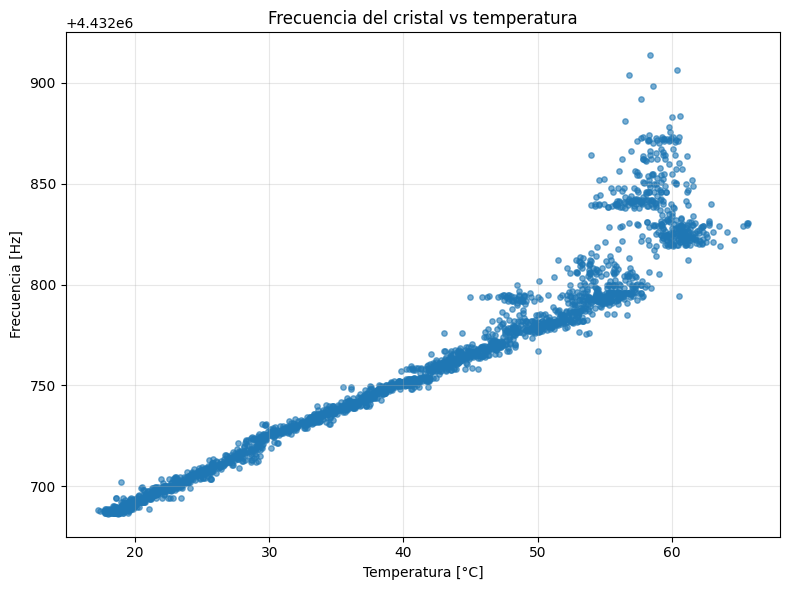

In [2]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CARGAR DATOS
# ============================================================

archivo = "medicion_f_vs_T_1.csv"

df = pd.read_csv(archivo, comment="#")

# Eliminar filas con datos faltantes
df = df.dropna(subset=[
    "timestamp_s",
    "f_sensor_hz",
    "temp_c"
])

t = df["timestamp_s"].to_numpy()
f = df["f_sensor_hz"].to_numpy()
T = df["temp_c"].to_numpy()

# ============================================================
# 1. FRECUENCIA VS TIEMPO
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(t, f, color="tab:blue", linewidth=1)

plt.xlabel("Tiempo [s]")
plt.ylabel("Frecuencia [Hz]")
plt.title("Frecuencia del cristal vs tiempo")

plt.grid(True, alpha=0.3)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()

# ============================================================
# 2. TEMPERATURA VS TIEMPO
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(t, T, color="tab:red", linewidth=1)

plt.xlabel("Tiempo [s]")
plt.ylabel("Temperatura [°C]")
plt.title("Temperatura vs tiempo")

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 3. FRECUENCIA VS TEMPERATURA (SCATTER)
# ============================================================

plt.figure(figsize=(8, 6))

plt.scatter(
    T,
    f,
    s=15,
    alpha=0.6,
    color="tab:blue"
)

plt.xlabel("Temperatura [°C]")
plt.ylabel("Frecuencia [Hz]")
plt.title("Frecuencia del cristal vs temperatura")

plt.grid(True, alpha=0.3)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()
